# Linear Regression Playground (TO FILL)

> **Follow-Along version**
> Cells marked with `TODO` have small blanks for you to fill in.  
> Keep it simple: a few lines each.

In [5]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
# Reproducibility
rng = np.random.default_rng(42)

# Utility: mean squared error
def mse(y_true, y_pred):
    """Return the mean squared error between y_true and y_pred.
    y_true: (n,), y_pred: (n,) → scalar
    """
    # TODO: compute the average of squared differences
    return np.mean((y_true - y_pred) ** 2)


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/homebrew/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/homebrew/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/opt/homebrew/anaconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/hom

AttributeError: _ARRAY_API not found


A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.

Traceback (most recent call last):  File "<frozen runpy>", line 198, in _run_module_as_main
  File "<frozen runpy>", line 88, in _run_code
  File "/opt/homebrew/anaconda3/lib/python3.12/site-packages/ipykernel_launcher.py", line 17, in <module>
    app.launch_new_instance()
  File "/opt/homebrew/anaconda3/lib/python3.12/site-packages/traitlets/config/application.py", line 1075, in launch_instance
    app.start()
  File "/opt/homebrew/anaconda3/lib/python3.12/site-packages/ipykernel/kernelapp.py", line 701, in start
    self.io_loop.start()
  File "/opt/hom

ImportError: 
A module that was compiled using NumPy 1.x cannot be run in
NumPy 2.4.2 as it may crash. To support both 1.x and 2.x
versions of NumPy, modules must be compiled with NumPy 2.0.
Some module may need to rebuild instead e.g. with 'pybind11>=2.12'.

If you are a user of the module, the easiest solution will be to
downgrade to 'numpy<2' or try to upgrade the affected module.
We expect that some modules will need time to support NumPy 2.



## Loading training set

In [6]:
# Data domain
x_min, x_max = 0.0, 10.0

train_data = np.load("train_data.npz")
test_data = np.load("test_data.npz")

x_train = train_data["X"][:, 0]
y_train = train_data["y"]

x_test = test_data["X"][:, 0]
y_test = test_data["y"]

# Problem sizes
n_train = x_train.shape[0]
n_test = x_test.shape[0]

# Quick glance
print("Number of training samples =", n_train)
print("Number of test samples = ", n_test)

Number of training samples = 10
Number of test samples =  10


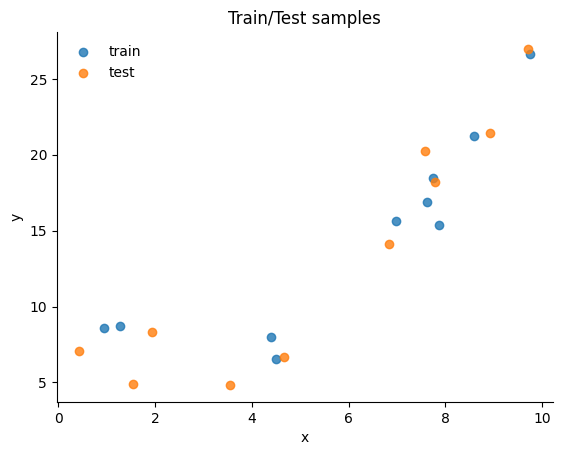

In [7]:
# Plot train & test data
xs = np.linspace(x_min, x_max, 400)
plt.figure()
plt.scatter(x_train, y_train, label="train", alpha=0.8)
plt.scatter(x_test,  y_test,  label="test",  alpha=0.8)
plt.xlabel("x")
plt.ylabel("y")
plt.title("Train/Test samples")
plt.legend(frameon=False)
sns.despine()
plt.show()

## 2) Constant Model

First we suppose we're trying to learn a constant fit as $f^{(0)}_b(x) = b$, to do so we consider the loss
$L(b) = \frac{1}{n}\sum_{i=1}^n (y_i - b)^2$.

*Question:* what value of $b$ minimises the loss? 
{}
*Question:* observe the training loss $L$, is it indeed convex? is the test loss necessarily convex? 

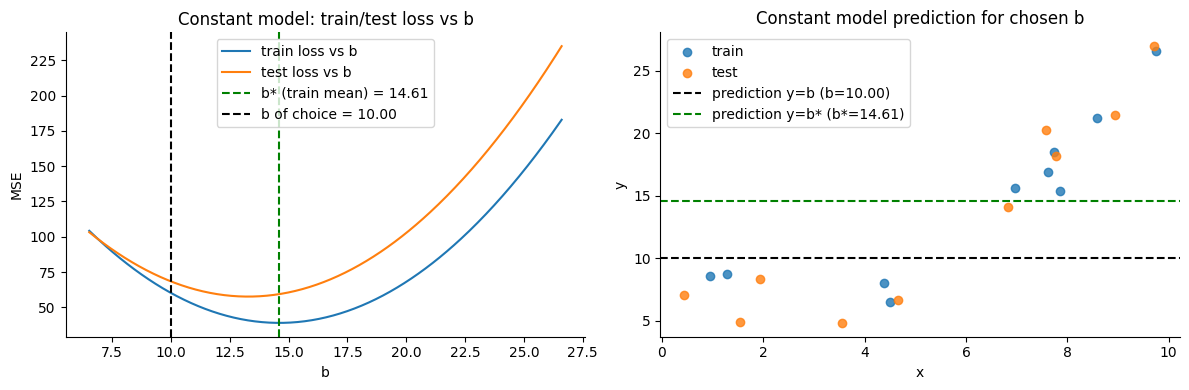

Train MSE (constant): 38.95
Test  MSE (constant): 59.34


In [8]:
# Grid of b values to visualize train MSE
b_grid = np.linspace(np.min(y_train), np.max(y_train), 400)

train_mse_grid = [mse(y_train, np.full_like(y_train, b)) for b in b_grid]
test_mse_grid = [mse(y_test, np.full_like(y_test, b)) for b in b_grid]

# Best constant by train mean of y
b_star_train = np.mean(y_train) # TODO: fill in the optimal value of b

b_choice = 10    # <- change this to any b you want

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# --- Left: MSE curves vs b ---
ax1.plot(b_grid, train_mse_grid, label="train loss vs b")
ax1.plot(b_grid, test_mse_grid,  label="test loss vs b")
ax1.axvline(b_star_train, linestyle="--",
            label=f"b* (train mean) = {b_star_train:.2f}", color = 'g')
ax1.axvline(b_choice, linestyle="--",
            label=f"b of choice = {b_choice:.2f}", color = 'k')
ax1.set_xlabel("b")
ax1.set_ylabel("MSE")
ax1.set_title("Constant model: train/test loss vs b")
ax1.legend()

# --- Right: prediction function y = b_choice ---
xs = np.linspace(x_min, x_max, 400)
ax2.scatter(x_train, y_train, label="train", alpha=0.8)
ax2.scatter(x_test,  y_test,  label="test",  alpha=0.8)
ax2.axhline(b_choice, linestyle="--", label=f"prediction y=b (b={b_choice:.2f})", color = 'k')
ax2.axhline(b_star_train, linestyle="--", label=f"prediction y=b* (b*={b_star_train:.2f})", color = 'g')

ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_title("Constant model prediction for chosen b")
ax2.legend()

plt.tight_layout()
sns.despine()
plt.show()

print(f"Train MSE (constant): {mse(y_train, np.full_like(y_train, b_star_train)):.2f}")
print(f"Test  MSE (constant): {mse(y_test,  np.full_like(y_test, b_star_train)):.2f}")

*Question:* what if we considered the training loss $\frac{1}{n}\sum_{i=1}^n |y_i - b|$? what would be the value of $b$ which minimises the loss?

> It would be the median

## 3) Linear Model: Level Lines of the Loss

Now we consider a "more complex" model $f^{(1)}_{a, b}(x)=ax+b$.

We consider the **training loss** $L(a,b) = \frac{1}{n}\sum_{i=1}^n (y_i - (a x_i + b))^2$. 

*Question:* Recall how $L$ can be re-written as $L(w) = \frac{1}{n}\sum_{i=1}^n (y_i - \langle w, \phi_1(x_i) \rangle)^2$. i.e. $w = [a,b]$, $\phi_1(x) = ??$ $\boxed{\phi_1(x)=\begin{bmatrix}x\\1\end{bmatrix}}.$

*Question:* Can we reach zero-training loss? 
No

### Naive approach: grid search

*Question:* In the left plot below, what do the lines correspond to?
> They correspond to the level lines of the loss function

*Question:* play around with various values of $a$ and $b$, and understand the difference between the loss function plot (left) and the prediction function plot (right)
> Done

*Question:* In the code below, play around with the number of points in the grid.
> More points $\implies$ better solution

<>:33: SyntaxWarning: invalid escape sequence '\s'
<>:33: SyntaxWarning: invalid escape sequence '\s'
/var/folders/gk/r166p6nx2bb5zf2rlwww8fc00000gn/T/ipykernel_18444/1105279132.py:33: SyntaxWarning: invalid escape sequence '\s'
  ax1.scatter(0,14.61, marker = "*", color = "red", s = 80, label = "Previous $b^\star$")


Best values for a and b after the grid search = 1.86, 3.49


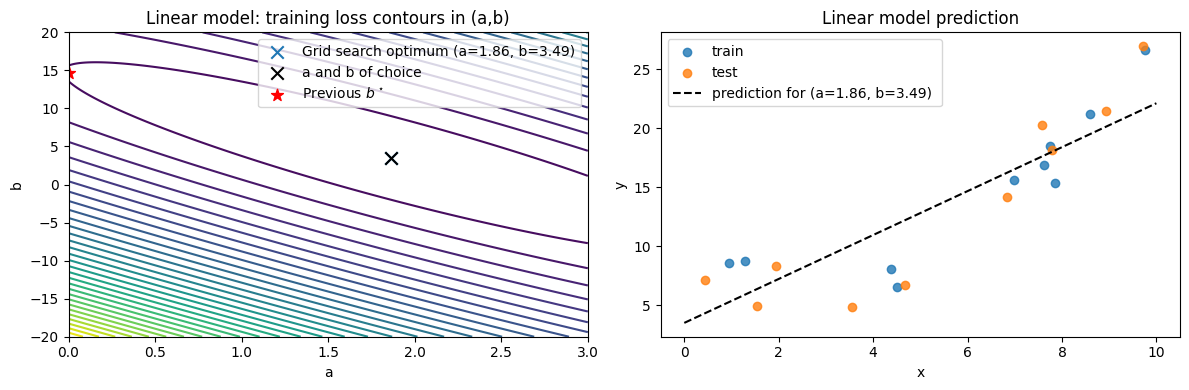

In [9]:
# Define loss grid
a_vals = np.linspace(0, 3.0, 500)  # <--- you can play with the number of points in the grid, observe how it affects the recovered solution
b_vals = np.linspace(-20.0, 20.0, 500)     # <--- you can play with the number of points in the grid
A, B = np.meshgrid(a_vals, b_vals, indexing='ij')  # (len(a), len(b))

# Compute L(a,b) grid
L = np.zeros((len(a_vals), len(b_vals)))
for i, a in enumerate(a_vals):
    for j, b in enumerate(b_vals):
        # TODO: compute y_pred 
        y_pred = a * x_train + b
        # TODO: compute the associated training loss
        L[i, j] = 1/len(x_train)*np.sum((y_train - y_pred)**2)

# get the "best" value a_star, b_star
ia, ib = np.unravel_index(np.argmin(L), L.shape)
a_best_grid = a_vals[ia]
b_best_grid = b_vals[ib]
print("Best values for a and b after the grid search = {:.2f}, {:.2f}".format(a_best_grid, b_best_grid))


#------- choose values of a and b ----
a_choice, b_choice = 1, 3
a_choice, b_choice = a_best_grid, b_best_grid
        
# Plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# --- Left: MSE curves ---
ax1.contour(A, B, L, levels=30)
ax1.scatter([a_best_grid], [b_best_grid], marker="x", s=80, label=f"Grid search optimum (a={a_best_grid:.2f}, b={b_best_grid:.2f})")
ax1.scatter([a_choice], [b_choice], marker="x", s=80, color = 'k', label="a and b of choice")
ax1.scatter(0,14.61, marker = "*", color = "red", s = 80, label = "Previous $b^\star$")
ax1.set_xlabel("a")
ax1.set_ylabel("b")
ax1.set_title("Linear model: training loss contours in (a,b)")
ax1.legend()

# --- Right: prediction function ---
xs = np.linspace(x_min, x_max, 400)
ax2.scatter(x_train, y_train, label="train", alpha=0.8)
ax2.scatter(x_test,  y_test,  label="test",  alpha=0.8)
ax2.plot(xs, a_choice * xs + b_choice, linestyle="--", label=f"prediction for (a={a_choice:.2f}, b={b_choice:.2f}) ", color = 'k')

ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_title("Linear model prediction")
ax2.legend()

plt.tight_layout()
plt.show()

*Question:* What's the complexity of this grid search in terms of $n$, $d$ and the size of the grid?

> It's $\Theta(n_a \cdot n_b \cdot n\cdot d)$

*Question:* how is convexity observed in the above contour line plot?

> All level lines are ellipses, that are convex

*Question:* Where can the loss curve from the constant model be seen in the left plot above? Can you find again the previous $b^\star = 14.61$ value? 

> It's the y-axis line, the poiunt $b^\star$ is the intersection of the ellipse of level line with that axis

## Brute force: closed form solution

*Question:* Write down the feature matrix and recall the formula which gives the optimal solution? What does $d$ correspond to here? Is it the dimension of the input datapoints?

In [10]:
# Build design matrix
Phi2_train = np.column_stack([np.ones(n_train), x_train]) # n x d=2 matrix
Phi2_test = np.column_stack([np.ones(n_test), x_test])    # n x d=2 matrix

# Closed-form LS 
# TODO: compute the optimal values of b and a 
w_star = np.linalg.solve(Phi2_train.T@Phi2_train, Phi2_train.T@y_train) # w = [b, a] and not [a, b]! Do you see why?
b_star, a_star = w_star       

# Keep the line below commented, it's just to say that there are smarter ways of getting the solution
# w_star = , *_ = np.linalg.lstsq(Phi1_train, y_train, rcond=None)  <-- here numpy uses smarter ways of solving the problem

# TODO: compute train and test losses for w_star
best_train_d2 = mse(y_train, a_star * x_train + b)
best_test_d2 =  mse(y_test, a_star * x_test + b)

print(f"Train MSE (linear): {best_train_d2:.2f}")
print(f"Test  MSE (linear): {best_test_d2:.2f}")

Train MSE (linear): 283.42
Test  MSE (linear): 287.34


*Question:* how do the train and test losses compare to the ones from the constant model? 

*Question:* can the test loss be lower than the train loss? 

*Question:* What's the complexity in terms of $n$ and $d$ of computing $w^\star$? 

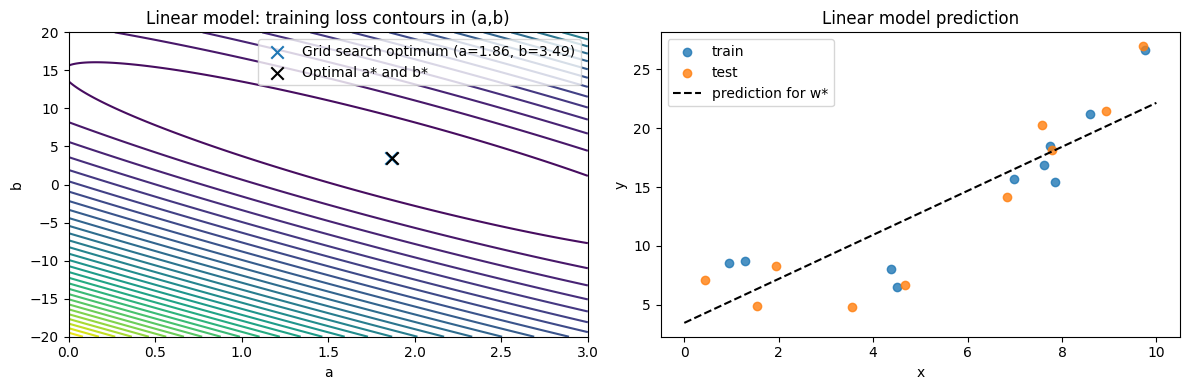

In [11]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# --- Left: MSE curves ---
ax1.contour(A, B, L, levels=30)
ax1.scatter([a_best_grid], [b_best_grid], marker="x", s=80, label=f"Grid search optimum (a={a_best_grid:.2f}, b={b_best_grid:.2f})")
ax1.scatter([a_star], [b_star], marker="x", s=80, color = 'k', label="Optimal a* and b*")
ax1.set_xlabel("a")
ax1.set_ylabel("b")
ax1.set_title("Linear model: training loss contours in (a,b)")
ax1.legend()

# --- Right: prediction function ---
xs = np.linspace(x_min, x_max, 400)
ax2.scatter(x_train, y_train, label="train", alpha=0.8)
ax2.scatter(x_test,  y_test,  label="test",  alpha=0.8)
# TODO: plot the prediction function
ax2.plot(xs, a_star * xs + b_star, linestyle="--", label=f"prediction for w*", color = 'k')

ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_title("Linear model prediction")
ax2.legend()

plt.tight_layout()
plt.show()

*TODO:* plot the level lines of the test loss. Are they the same as those of the train loss?
> They are not the same

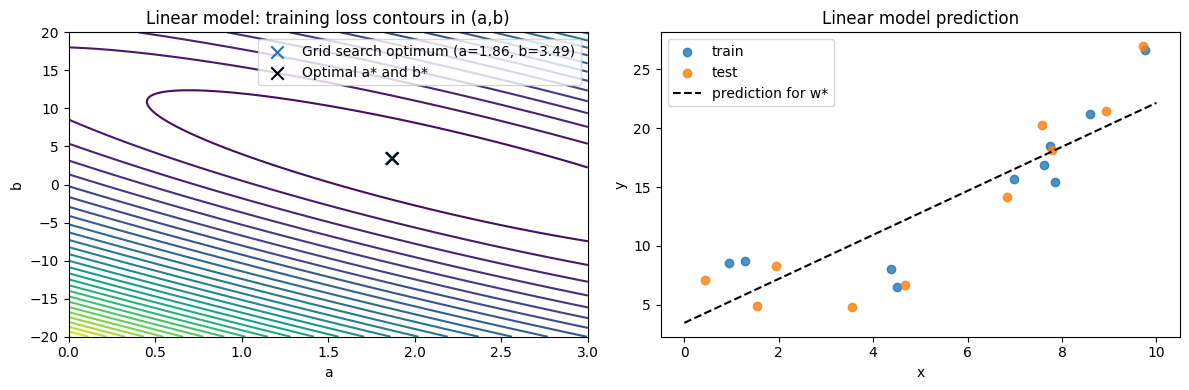

In [12]:
# Level lines of the test set

L_test = np.zeros((len(a_vals), len(b_vals)))
for i, a in enumerate(a_vals):
    for j, b in enumerate(b_vals):
        # TODO: compute y_pred 
        y_pred = a * x_test + b
        # TODO: compute the associated training loss
        L_test[i, j] = 1/len(x_test)*np.sum((y_test - y_pred)**2)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

# --- Left: MSE curves ---
ax1.contour(A, B, L_test, levels=30)
ax1.scatter([a_best_grid], [b_best_grid], marker="x", s=80, label=f"Grid search optimum (a={a_best_grid:.2f}, b={b_best_grid:.2f})")
ax1.scatter([a_star], [b_star], marker="x", s=80, color = 'k', label="Optimal a* and b*")
ax1.set_xlabel("a")
ax1.set_ylabel("b")
ax1.set_title("Linear model: training loss contours in (a,b)")
ax1.legend()

# --- Right: prediction function ---
xs = np.linspace(x_min, x_max, 400)
ax2.scatter(x_train, y_train, label="train", alpha=0.8)
ax2.scatter(x_test,  y_test,  label="test",  alpha=0.8)
# TODO: plot the prediction function
ax2.plot(xs, a_star * xs + b_star, linestyle="--", label=f"prediction for w*", color = 'k')

ax2.set_xlabel("x")
ax2.set_ylabel("y")
ax2.set_title("Linear model prediction")
ax2.legend()

plt.tight_layout()
plt.show()

## With gradient optimisation

*Question:* Write down the gradient of $L(w) = \frac{1}{n}\sum_{i=1}^n (y_i - \langle w, \phi_1(x_i) \rangle)^2$? 

$\Delta L$ calculation

$L(w) = 1/n \sum_{i=1}^n (<w, \phi(x_i)> - y_i)^2$

$\nabla L(w) = 2 / n \sum_{i=1}^n (<w, \phi(x_i)> - y_i)*\phi(x_i) $

In [13]:
def gd_least_squares(X, y, X_test, y_test, steps=200, lr=1e-2, w0=None):
    n, d = X.shape
    w = np.zeros(d) if w0 is None else w0.copy()
    losses, test_losses = [], []
    ws = [w.copy()]
    for t in range(steps):
        # TODO: compute the gradient 
        grad = 2/n * (w @ X.T - y) @ X
        w -= lr * grad
        losses.append(mse(y, X @ w))
        test_losses.append(mse(y_test, X_test @ w))
        ws.append(w.copy())
    return np.array(ws), np.array(losses), np.array(test_losses)

def sgd_least_squares(X, y, X_test, y_test, steps=1000, lr=1e-2, w0=None):
    n, d = X.shape
    w = np.zeros(d) if w0 is None else w0.copy()
    losses, test_losses, ws = [], [], [w.copy()]
    for k in range(steps):
        ik = np.random.randint(n)                # choose a data point
        xik = X[ik]                           # shape (d,)
        yik = y[ik]
        # TODO: compute the stochastic gradient 
        grad = 2 * (xik @ w - yik) * xik     
        w -= lr * grad
        losses.append(mse(y, X @ w))        # full-train loss for tracking
        test_losses.append(mse(y_test, X_test @ w))
        ws.append(w.copy())
    return np.array(ws), np.array(losses), np.array(test_losses)

*Question:* can the training loss increase along the optimisation path for gradient descent? and what about for stochastic gradient descent?

*Question:* are all the SGD runs the same?

*Question:* can constant stepsize SGD converge in this setting? What assumption is necessary over the training dataset in order to hope for constant stepsize SGD to converge?

*Question:* play around with the stepsizes and number of iterations below.

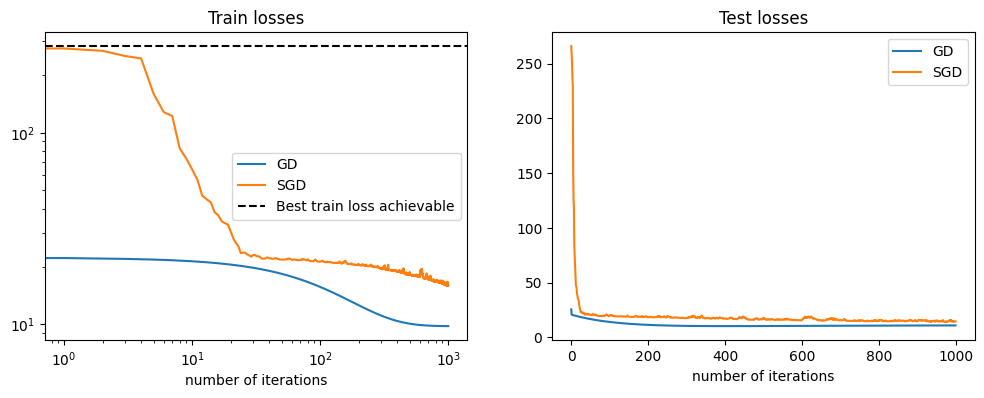

In [14]:
# ---- Run GD & SGD on the linear model (d=2) ----
steps_gd = 1000
steps_sgd = 1000
lr_gd = 1e-2
lr_sgd = 1 * 1e-3

w0 = np.array([-5.0, 0.5])  # you can pick anything here
ws_gd, losses_gd, test_losses_gd = gd_least_squares(Phi2_train, y_train, Phi2_test, y_test, steps=steps_gd, lr=lr_gd, w0 = w0)
ws_sgd, losses_sgd, test_losses_sgd = sgd_least_squares(Phi2_train, y_train, Phi2_test, y_test, steps=steps_sgd, lr=lr_sgd, w0 = w0)

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

ax1.loglog(losses_gd, label = 'GD')
ax1.loglog(losses_sgd, label = 'SGD')
ax1.axhline(best_train_d2, color = 'k', label = 'Best train loss achievable', linestyle = '--')
ax1.set_xlabel('number of iterations')
ax1.set_title('Train losses')
ax1.legend()

ax2.plot(test_losses_gd, label = 'GD')
ax2.plot(test_losses_sgd, label = 'SGD')
ax2.set_xlabel('number of iterations')
ax2.set_title('Test losses')
ax2.legend()
plt.show()

In [15]:
# Helpers to get the current (a,b) from trajectories
def get_ab(ws, k):
    b_k, a_k = ws[k, 0], ws[k, 1]  # w = [b, a]
    return a_k, b_k

# Plot function controlled by widgets
def show_iter(k=0, method='GD'):
    ws = ws_gd if method == 'GD' else ws_sgd
    a_k, b_k = get_ab(ws, k)

    fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))

    # --- Left: contours + trajectory up to k ---
    C = ax1.contour(A, B, L, levels=30)
    # ax1.clabel(C, inline=True, fontsize=8)

    traj = ws[:k+1]
    ax1.scatter(traj[:, 1], traj[:, 0], linewidth=1.5, label=f"{method} trajectory (0→{k})")
    ax1.scatter([a_k], [b_k], s=60, label=f"{method} @ k={k}")
    ax1.scatter([a_star], [b_star], marker="*", s=120, label="Closed-form LS")

    ax1.set_xlabel("a"); ax1.set_ylabel("b")
    ax1.set_title("Training loss contours with iterate")
    ax1.legend(loc="best")

    # --- Right: prediction at iteration k ---
    xs = np.linspace(x_min, x_max, 400)
    ax2.scatter(x_train, y_train, label="train", alpha=0.7)
    ax2.scatter(x_test,  y_test,  label="test",  alpha=0.7)
    ax2.plot(xs, a_k*xs + b_k, linewidth=2.0, label=f"{method} k={k}")
    ax2.plot(xs, a_star*xs + b_star, linewidth=2.0, label="Closed-form LS")

    ax2.set_xlabel("x"); ax2.set_ylabel("y")
    ax2.set_title("Prediction function at iteration k")
    ax2.legend()

    plt.tight_layout()
    plt.show()

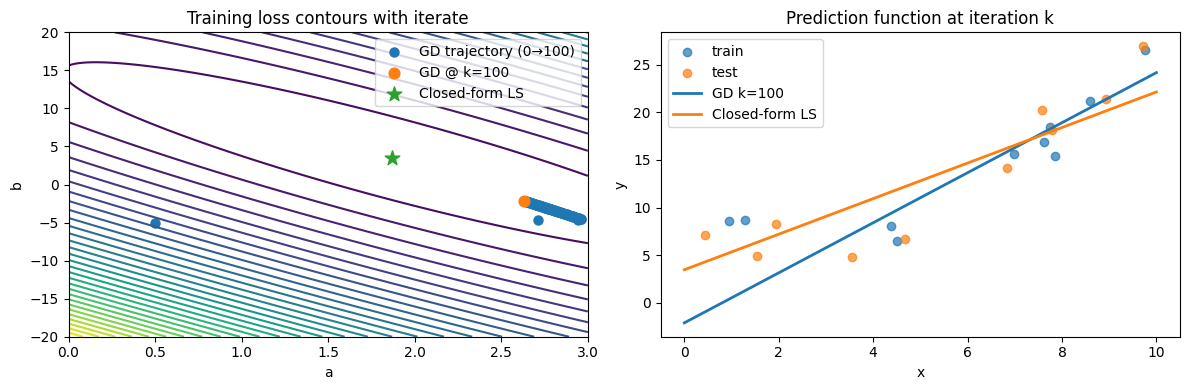

In [16]:
show_iter(k=100, method='GD')

*Question:* wait but how come the trajectory is not orthogonal to the level lines as you mentioned??!

## 4) Going further with polynomial expansions

Now we consider a "more complex" model $f^{(d)}_w(x)=w_0 + w_1 x + \cdots + w_{d} x^{d}$. 

We consider the **training loss** $L(w) = \frac{1}{n}\sum_{i=1}^n (y_i - f^{(d)}_w(x_i))^2$. 

*Question:* Recall how $L$ can be re-written as $L(w) = \frac{1}{n}\sum_{i=1}^n (y_i - \langle w, \phi_d(x_i) \rangle)^2$. i.e. $w = ??$, $\phi_d(x_i) = ??$

> $w = (w_1, ..., w_n),\; \phi_d(x_i) = (1, x_i, ..., x_i^d) \in \mathbb{R}^{d+1}$

*Question:* what is $d$ here? in which space does $w$ live?

> It's the degree of the polynomial, $w \in \mathbb{R}^{d+1}$

*Question:* Can we reach zero-training loss? If so, for which values of $d$? 

> For $d = n-1$, where $n$ is the number of points

In [17]:
def make_vandermonde(x, d):
    # Columns: x^0, x^1, ..., x^{d-1}
    powers = [np.ones_like(x)]
    for k in range(1, d+1):
        powers.append(powers[-1] * x)
    return np.column_stack(powers)

def fit_pinv(X, y):
    # think of np.linalg.pinv(X)  as computing X.T (X X.T)^{-1} or (X.T X)^{-1} X.T depending on d < n or not 
    return np.linalg.pinv(X) @ y

*Question:* What do we expect the train loss to do as $d$ increases? and the test loss?

In [26]:
# Degrees to evaluate/plot
degrees_to_evaluate = list(range(0, 15))  # d = 0..14

train_mse_by_d = []
test_mse_by_d = []

fitted_by_d = {}

for d in degrees_to_evaluate:
    # TODO: construct feature matrix for train and test, compute optimal solution using train, save train and test losses
    # HINT: use the make_vandermonde(x, d) and fit_pinv(X, y) functions from the cell above!
    Xd_train = make_vandermonde(x_train, d)
    Xd_test  = make_vandermonde(x_test, d)
    w = fit_pinv(Xd_train, y_train)
    fitted_by_d[d] = w
    train_mse_by_d.append(mse(y_train, w @ Xd_train.T))
    test_mse_by_d.append(mse(y_test, w @ Xd_test.T))

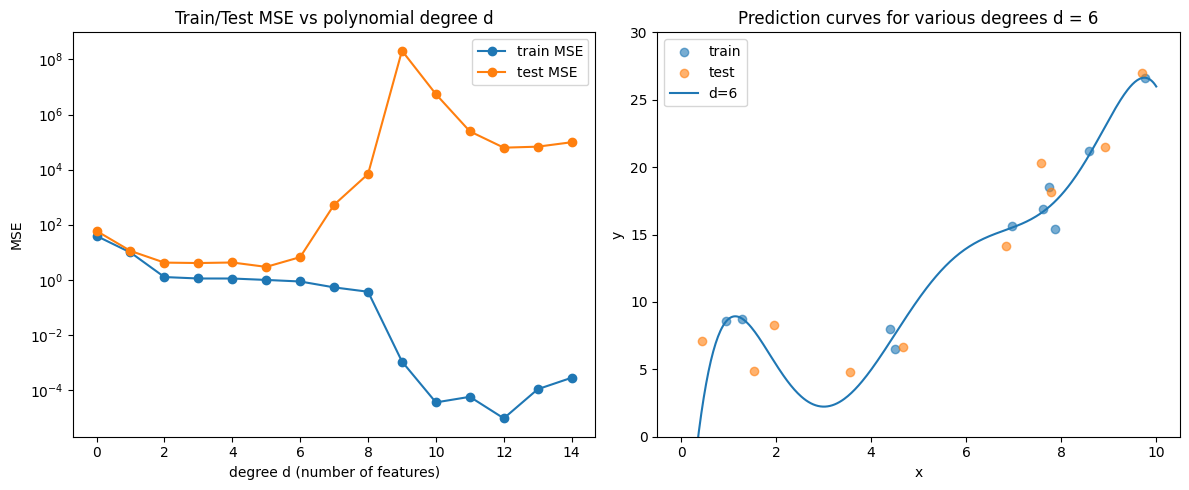

In [31]:
# Plot train/test MSE vs d
ds = np.array(degrees_to_evaluate)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# --- Left plot: Train/Test MSE ---
axes[0].semilogy(ds, train_mse_by_d, marker="o", label="train MSE")
axes[0].semilogy(ds, test_mse_by_d,  marker="o", label="test MSE")
axes[0].set_xlabel("degree d (number of features)")
axes[0].set_ylabel("MSE")
axes[0].set_title("Train/Test MSE vs polynomial degree d")
# axes[0].set_ylim([0, 30])
axes[0].legend()

# --- Right plot: Prediction functions ---
d = 6   # <-- play with the value of d here

xs_dense = np.linspace(x_min, x_max, 400)
axes[1].scatter(x_train, y_train, label="train", alpha=0.6)
axes[1].scatter(x_test,  y_test,  label="test",  alpha=0.6)

Xd_dense = make_vandermonde(xs_dense, d)
w = fitted_by_d.get(d)
y_pred_dense = Xd_dense @ w
axes[1].plot(xs_dense, y_pred_dense, label=f"d={d}")
axes[1].set_ylim(0, 30)
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Prediction curves for various degrees d = {}".format(d))
axes[1].legend()

plt.tight_layout()
plt.show()

*Question:* what value of polynomial expansion degree would one pick according to the above plots?

> One would pick $ d = 5 $ that minimizes the test MSE

*Question:* comment on the train and test loss curves

> You can see how before $d = 6$ the polynomials adjust increasingly better, and after that point they start overfitting the data, and thus the test MSE goes up.

*Question:* how is the fact that $L(w^\star) = 0$ represented in the above right plot?

> By the polynomial crossing all the blue points

## Using regularisation

To avoid the catastrophic overfitting observed above, we can use $\ell_2$ regularisation (called weight decay in deep learning), this corresponds to minimising the regularised loss $L_\lambda(w) = L(w) + \lambda \Vert w \Vert^2 = \frac{1}{n}\sum_{i=1}^n (y_i - f^{(d)}_w(x_i))^2 +  \lambda \Vert w \Vert^2$. We can then denote $w^\star_\lambda = \arg \min L_\lambda$.

*Question:* for $\lambda \geq 0$, is $L_\lambda$ a convex function? 

> Yes it is convex, as the hessian is $\nabla^2 L_\lambda(w)=\frac{2}{n}X^\top X+2\lambda I.$

*Question:* for $\lambda \geq 0$, give the formula for $w^\star_\lambda$? 

> For $\lambda \geq 0 $ we will have that $w^\star_\lambda = \left( X^T X + n\lambda I \right)^{-1} X^T y $

*Question:* should we compute the test loss using the regularisation term too, or without? 

> The test loss should not be computed using regularization, as we wouldn't have the real loss.

*Question:* for $\lambda > 0$, can we have $L(w^\star_\lambda) = 0$?

> No, it's impossible unless all the data points were 0 and we fit a w = 0.

*Question:* what does $w^\star_\lambda$ converge to as $\lambda \to \infty$?

> It converges to 0.

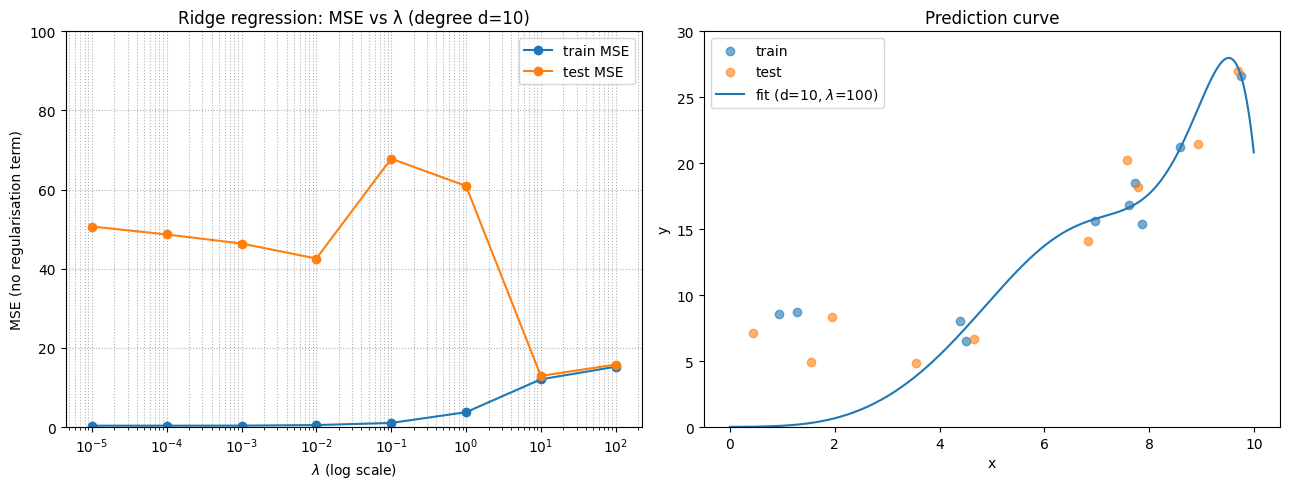

In [42]:
def fit_ridge(X, y, lam):
    # TODO: compute w^*_\lambda 
    n, d = X.shape
    return np.linalg.solve(X.T@X + n * lam * np.eye(d), X.T@y) 

# ---- Choose a polynomial degree to study vs λ ----
d =10   # <-- change this to whatever degree you want

# ---- Build design matrices for that degree ----
Xd_train = make_vandermonde(x_train, d)
Xd_test  = make_vandermonde(x_test,  d)

# ---- λ values to sweep ----
lambdas = np.array([1e-5, 1e-4, 1e-3, 1e-2, 1e-1, 1.0, 10.0, int(1e2)])

train_mse_by_lambda = []
test_mse_by_lambda  = []
weights_by_lambda   = {}

for lam in lambdas:
    w = fit_ridge(Xd_train, y_train, lam=lam)
    weights_by_lambda[lam] = w
    # pure prediction errors (no reg term included)
    train_mse_by_lambda.append(mse(y_train, Xd_train @ w))
    test_mse_by_lambda.append(mse(y_test,  Xd_test  @ w))

# ---- Inspect a particular λ on a dense grid ----
lam_to_plot = 100 # <-- change if you want to visualise another λ

xs_dense = np.linspace(x_min, x_max, 400)
Xd_dense = make_vandermonde(xs_dense, d)
w_sel = weights_by_lambda[lam_to_plot]
y_pred_dense = Xd_dense @ w_sel

# ---- Plot both side by side ----
fig, axes = plt.subplots(1, 2, figsize=(13, 5))

# Left plot: Train/Test MSE vs λ
axes[0].plot(lambdas, train_mse_by_lambda, marker="o", label="train MSE")
axes[0].plot(lambdas, test_mse_by_lambda,  marker="o", label="test MSE")
axes[0].set_xscale("log")
axes[0].set_xlabel(r"$\lambda$ (log scale)")
axes[0].set_ylabel("MSE (no regularisation term)")
axes[0].set_title(f"Ridge regression: MSE vs λ (degree d={d})")
axes[0].set_ylim([0, 100])
axes[0].legend()
axes[0].grid(True, which="both", ls=":")

# Right plot: Prediction curve for one λ
axes[1].scatter(x_train, y_train, alpha=0.6, label="train")
axes[1].scatter(x_test,  y_test,  alpha=0.6, label="test")
axes[1].plot(xs_dense, y_pred_dense,
             label=rf"fit (d={d}, $\lambda$={lam_to_plot})")
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Prediction curve")
axes[1].legend()
axes[1].set_ylim(0, 30)

plt.tight_layout()
plt.show()

## Playing with other expansions

In [43]:
def make_sinus(x, d):
    # Columns: 1, sin(x), cos(x), ..., sin(d x), cos(d x)  -> 2d+1 features
    frequencies = [np.ones_like(x)]
    for k in range(1, d+1):
        frequencies.append(np.sin(k * x))
        frequencies.append(np.cos(k * x))
    return np.column_stack(frequencies)

In [44]:
# Maximum frequencies to evaluate/plot
freqs = list(range(0, 10))  # freq = 0..9

train_mse_by_freq = []
test_mse_by_freq = []

fitted_by_freq = {}

for freq in freqs:
    Xd_train = make_sinus(x_train, freq)
    Xd_test  = make_sinus(x_test,  freq)
    w = fit_pinv(Xd_train, y_train)
    fitted_by_freq[freq] = w
    train_mse_by_freq.append(mse(y_train, Xd_train @ w))
    test_mse_by_freq.append(mse(y_test,  Xd_test  @ w))

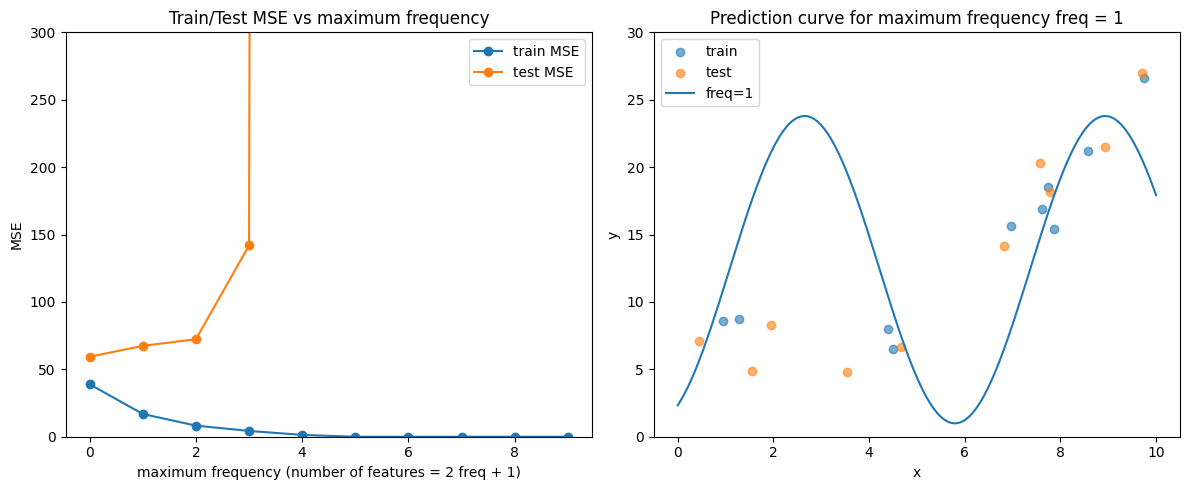

In [50]:
# Plot train/test MSE vs freq
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# --- Left plot: Train/Test MSE ---
axes[0].plot(freqs, train_mse_by_freq, marker="o", label="train MSE")
axes[0].plot(freqs, test_mse_by_freq,  marker="o", label="test MSE")
axes[0].set_xlabel("maximum frequency (number of features = 2 freq + 1)")
axes[0].set_ylabel("MSE")
axes[0].set_title("Train/Test MSE vs maximum frequency")
axes[0].set_ylim([0, 300])
axes[0].legend()

# --- Right plot: Prediction functions ---
freq = 1  # <-- play with the value of freq here

xs_dense = np.linspace(x_min, x_max, 400)
axes[1].scatter(x_train, y_train, label="train", alpha=0.6)
axes[1].scatter(x_test,  y_test,  label="test",  alpha=0.6)

Xd_dense = make_sinus(xs_dense, freq)
w = fitted_by_freq.get(freq)
y_pred_dense = Xd_dense @ w
axes[1].plot(xs_dense, y_pred_dense, label=f"freq={freq}")
axes[1].set_ylim(0, 30)
axes[1].set_xlabel("x")
axes[1].set_ylabel("y")
axes[1].set_title("Prediction curve for maximum frequency freq = {}".format(freq))
axes[1].legend()

plt.tight_layout()
plt.show()

# You've reached the end, bravo!